# Deliverable 1 : Binary classification

The aim of the deliverable 1 is to train a model on a large set of images and automate the selection of photos for annotation for the company.

The first step will be to import the images and treat or resize them in order to have a standart size and format that can be given to our model

We will first import our libs, for this part we will use tensoflow and pillow to read and resize the images

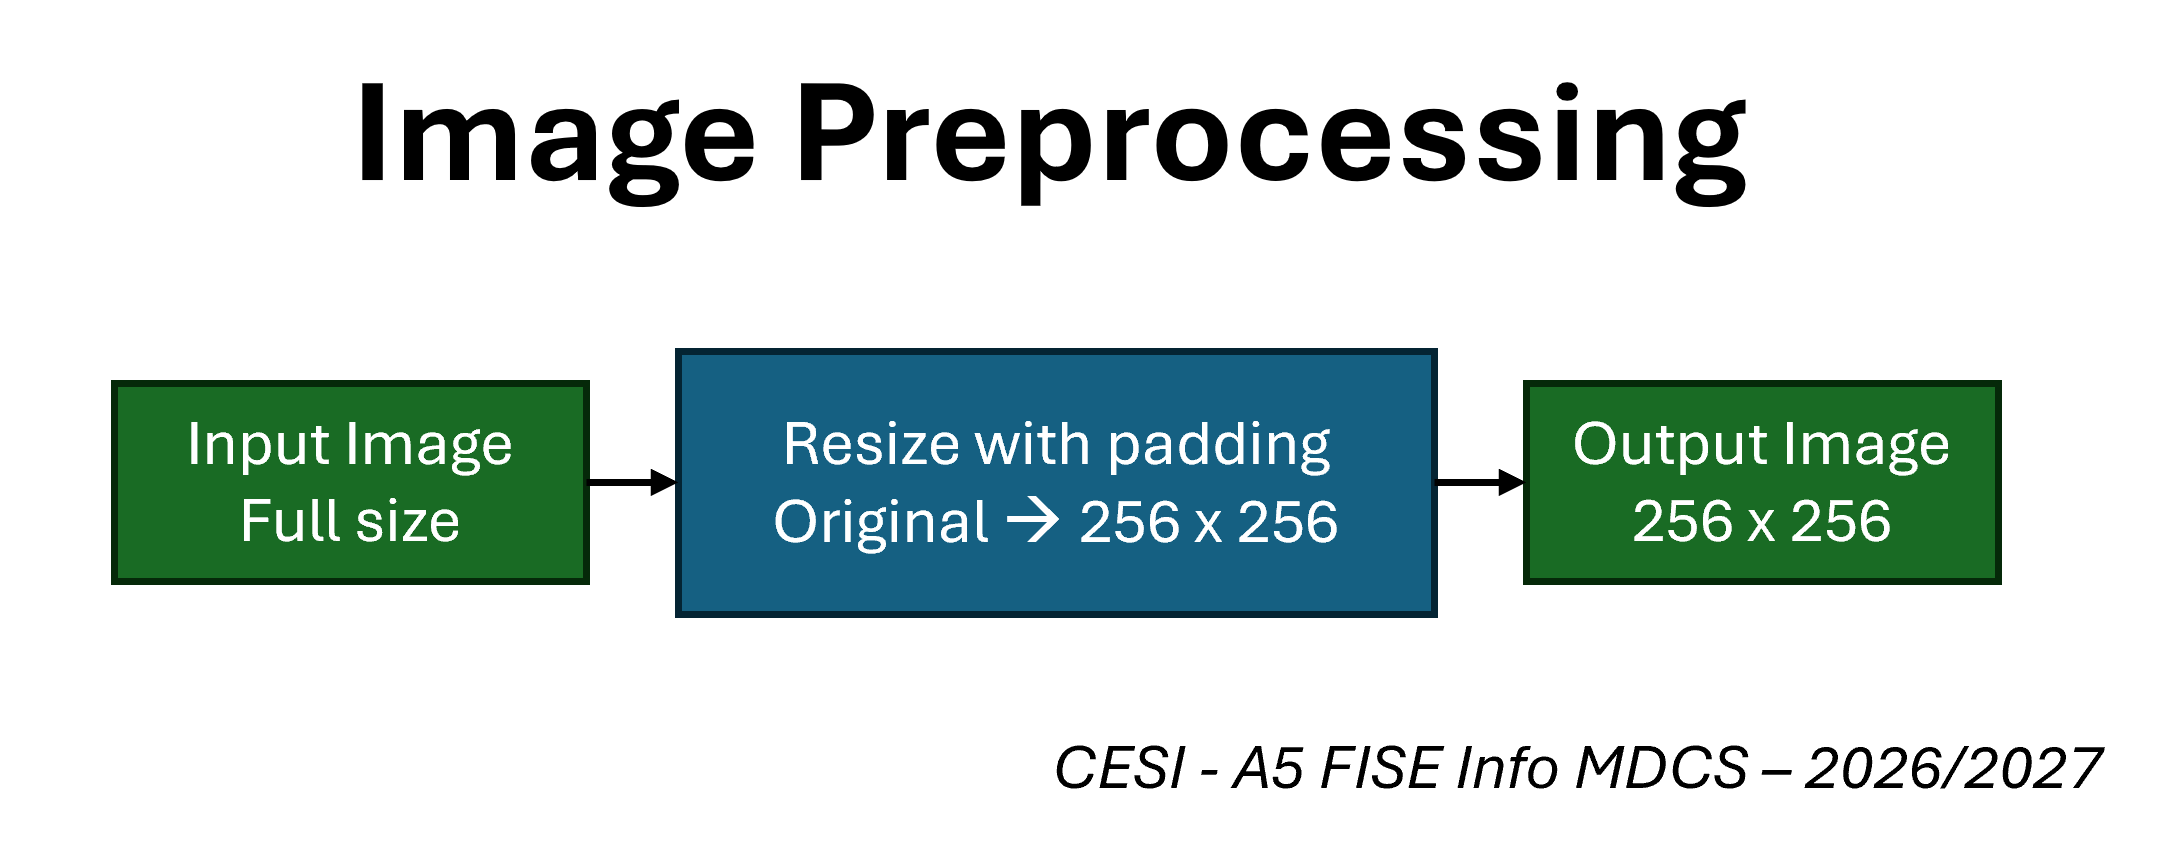

In [1]:
import tensorflow as tf
from PIL import Image
import os


In [2]:
"""
Please replace "Datasets" with the path to the folder containings the folders of Photo, Paintings, Skematics, Sketch and Text
"""

dataset_dir = "Datasets"

In [3]:
desired_size = 256

i = 0 # Just to update ever 1000 images

output_step1 = "Datasets_separated_step1_256"  # Should contain two folders: "Photo" and "Paintings" of size 256x256
output_step2 = "Datasets_separated_step2_256"  # Should contain the remaining folders : "Schematics", "Skecth" and "Text" of size 256x256

step1_labels = ["Photo", "Painting"]
step2_labels = ["Schematics", "Sketch", "Text"]

os.makedirs(output_step1, exist_ok=True)
os.makedirs(output_step2, exist_ok=True)

# Go through every folder contained in the given path
for label_name in os.listdir(dataset_dir):

    label_dir = os.path.join(dataset_dir, label_name)

    if not os.path.isdir(label_dir):
        continue

    if label_name in step1_labels:
        output_root = output_step1
    elif label_name in step2_labels:
        output_root = output_step2
    else:
        print(f"Catégorie ignorée : {label_name}")
        continue
    
    # Créer le sous-dossier de la catégorie
    processed_label_dir = os.path.join(output_root, label_name)
    os.makedirs(processed_label_dir, exist_ok=True)

    for filename in os.listdir(label_dir):

        filepath = os.path.join(label_dir, filename)

        if not os.path.isfile(filepath):
            continue

        if i % 1000 == 0:
            print("Nombre d'images traitées :", i)

        try:
            # Ouvrir et convertir l'image en RGB
            with Image.open(filepath) as img:
                img = img.convert("RGB")

                # Conversion en tenseur TensorFlow
                image = tf.convert_to_tensor(
                    __import__("numpy").array(img)
                )

                # Redimensionnement en conservant les proportions
                image = tf.image.resize_with_pad(
                    image,
                    target_height=desired_size,
                    target_width=desired_size
                )

                # Conversion en uint8
                image = tf.cast(image, tf.uint8)

                # Encodage JPEG
                image = tf.io.encode_jpeg(image, quality=95)

                # Enregistrer dans le bon dossier
                output_path = os.path.join(
                    processed_label_dir,
                    os.path.splitext(filename)[0] + ".jpg"
                )

                tf.io.write_file(output_path, image)

                i += 1

        except Exception as e:
            print(f"Erreur avec {filepath} : {e}")

print(f"\nTerminé ! Nombre d'images traitées : {i}")
    
    # for filename in os.listdir(label_dir):
    #     filepath = os.path.join(label_dir, filename)

    #     if os.path.isfile(filepath):
    #         if i % 1000 == 0:
    #             print("Number of images treated :", i)
    #         i += 1

    #         # For each new folder create an new arrival folder with the same name and _resized at the end
    #         processed_dir = label_dir + "_resized"
    #         processed_label_dir = os.path.join(
    #             processed_dir
    #         )

    #         os.makedirs(processed_label_dir, exist_ok=True)

    #         try:
    #             # Opening every image and converting them to size 256x256
    #             with Image.open(filepath) as img:

    #                 # Ensure each image have the same number of channels
    #                 img = img.convert("RGB")

    #                 # Convert pillow (numpy array) object to tf usable object
    #                 image = tf.convert_to_tensor(img)

    #                 # Resizing with pading to keep teh proportion for each image
    #                 image = tf.image.resize_with_pad(
    #                     image,
    #                     target_height=desired_size,
    #                     target_width=desired_size
    #                 )


    #                 image = tf.cast(image, tf.uint8)

    #                 # Save
    #                 image = tf.io.encode_jpeg(image, quality=95)

    #                 output_path = os.path.join(
    #                     processed_label_dir,
    #                     filename
    #                 )

    #                 tf.io.write_file(output_path, image)

    #         except Exception as e:
    #             print(f"Erreur avec {filepath} : {e}")

Nombre d'images traitées : 0
Nombre d'images traitées : 1000
Nombre d'images traitées : 2000
Nombre d'images traitées : 3000
Nombre d'images traitées : 4000
Nombre d'images traitées : 5000
Nombre d'images traitées : 6000
Nombre d'images traitées : 7000
Nombre d'images traitées : 8000
Nombre d'images traitées : 9000
Catégorie ignorée : Painting_resized
Nombre d'images traitées : 10000
Nombre d'images traitées : 11000
Nombre d'images traitées : 12000
Nombre d'images traitées : 13000
Nombre d'images traitées : 14000
Nombre d'images traitées : 15000
Nombre d'images traitées : 16000
Nombre d'images traitées : 17000
Nombre d'images traitées : 18000
Nombre d'images traitées : 19000
Catégorie ignorée : Photo_resized
Nombre d'images traitées : 20000
Nombre d'images traitées : 21000
Nombre d'images traitées : 22000
Nombre d'images traitées : 23000
Nombre d'images traitées : 24000
Nombre d'images traitées : 25000
Nombre d'images traitées : 26000
Nombre d'images traitées : 27000
Erreur avec Datase

With this code every image is now of size 256x256 (Some images that were 1 px large have been lossed but they were not important and could not be kept to train correctly)

Also the desktop.ini found in schematics will have been skipped by this code so it is not transmitted to the following part of the code

We have choosen the size 256x256 because it was slightly better than other smaller sizes. We could not take an higher size for picture since it would have taken too long to train our model with such parameters but it could have been a way to improve our model

In [4]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

We define number of batch size, epochs and workers. Our best results were with a batch size of 32 so that's what we kept for the deliverable.

In [5]:
# ============================================================
# CONFIGURATION
# ============================================================

BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.001

NUM_WORKERS = 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
print("Device :", device)

PyTorch : 2.14.1+cu130
CUDA disponible : True
Device : cuda


In [6]:
# ============================================================
# TRANSFORM
# ============================================================

transform = transforms.ToTensor()

The goal of this class it to load images little by little so the whole datasets is not in the ram at once

In [7]:
# ============================================================
# DATASET
# ============================================================

class ImageDataset(Dataset):

    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        image_path = self.image_paths[index]
        label = self.labels[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

Now that we have imported all the libraries and datasets, we can create our model following this architecture :


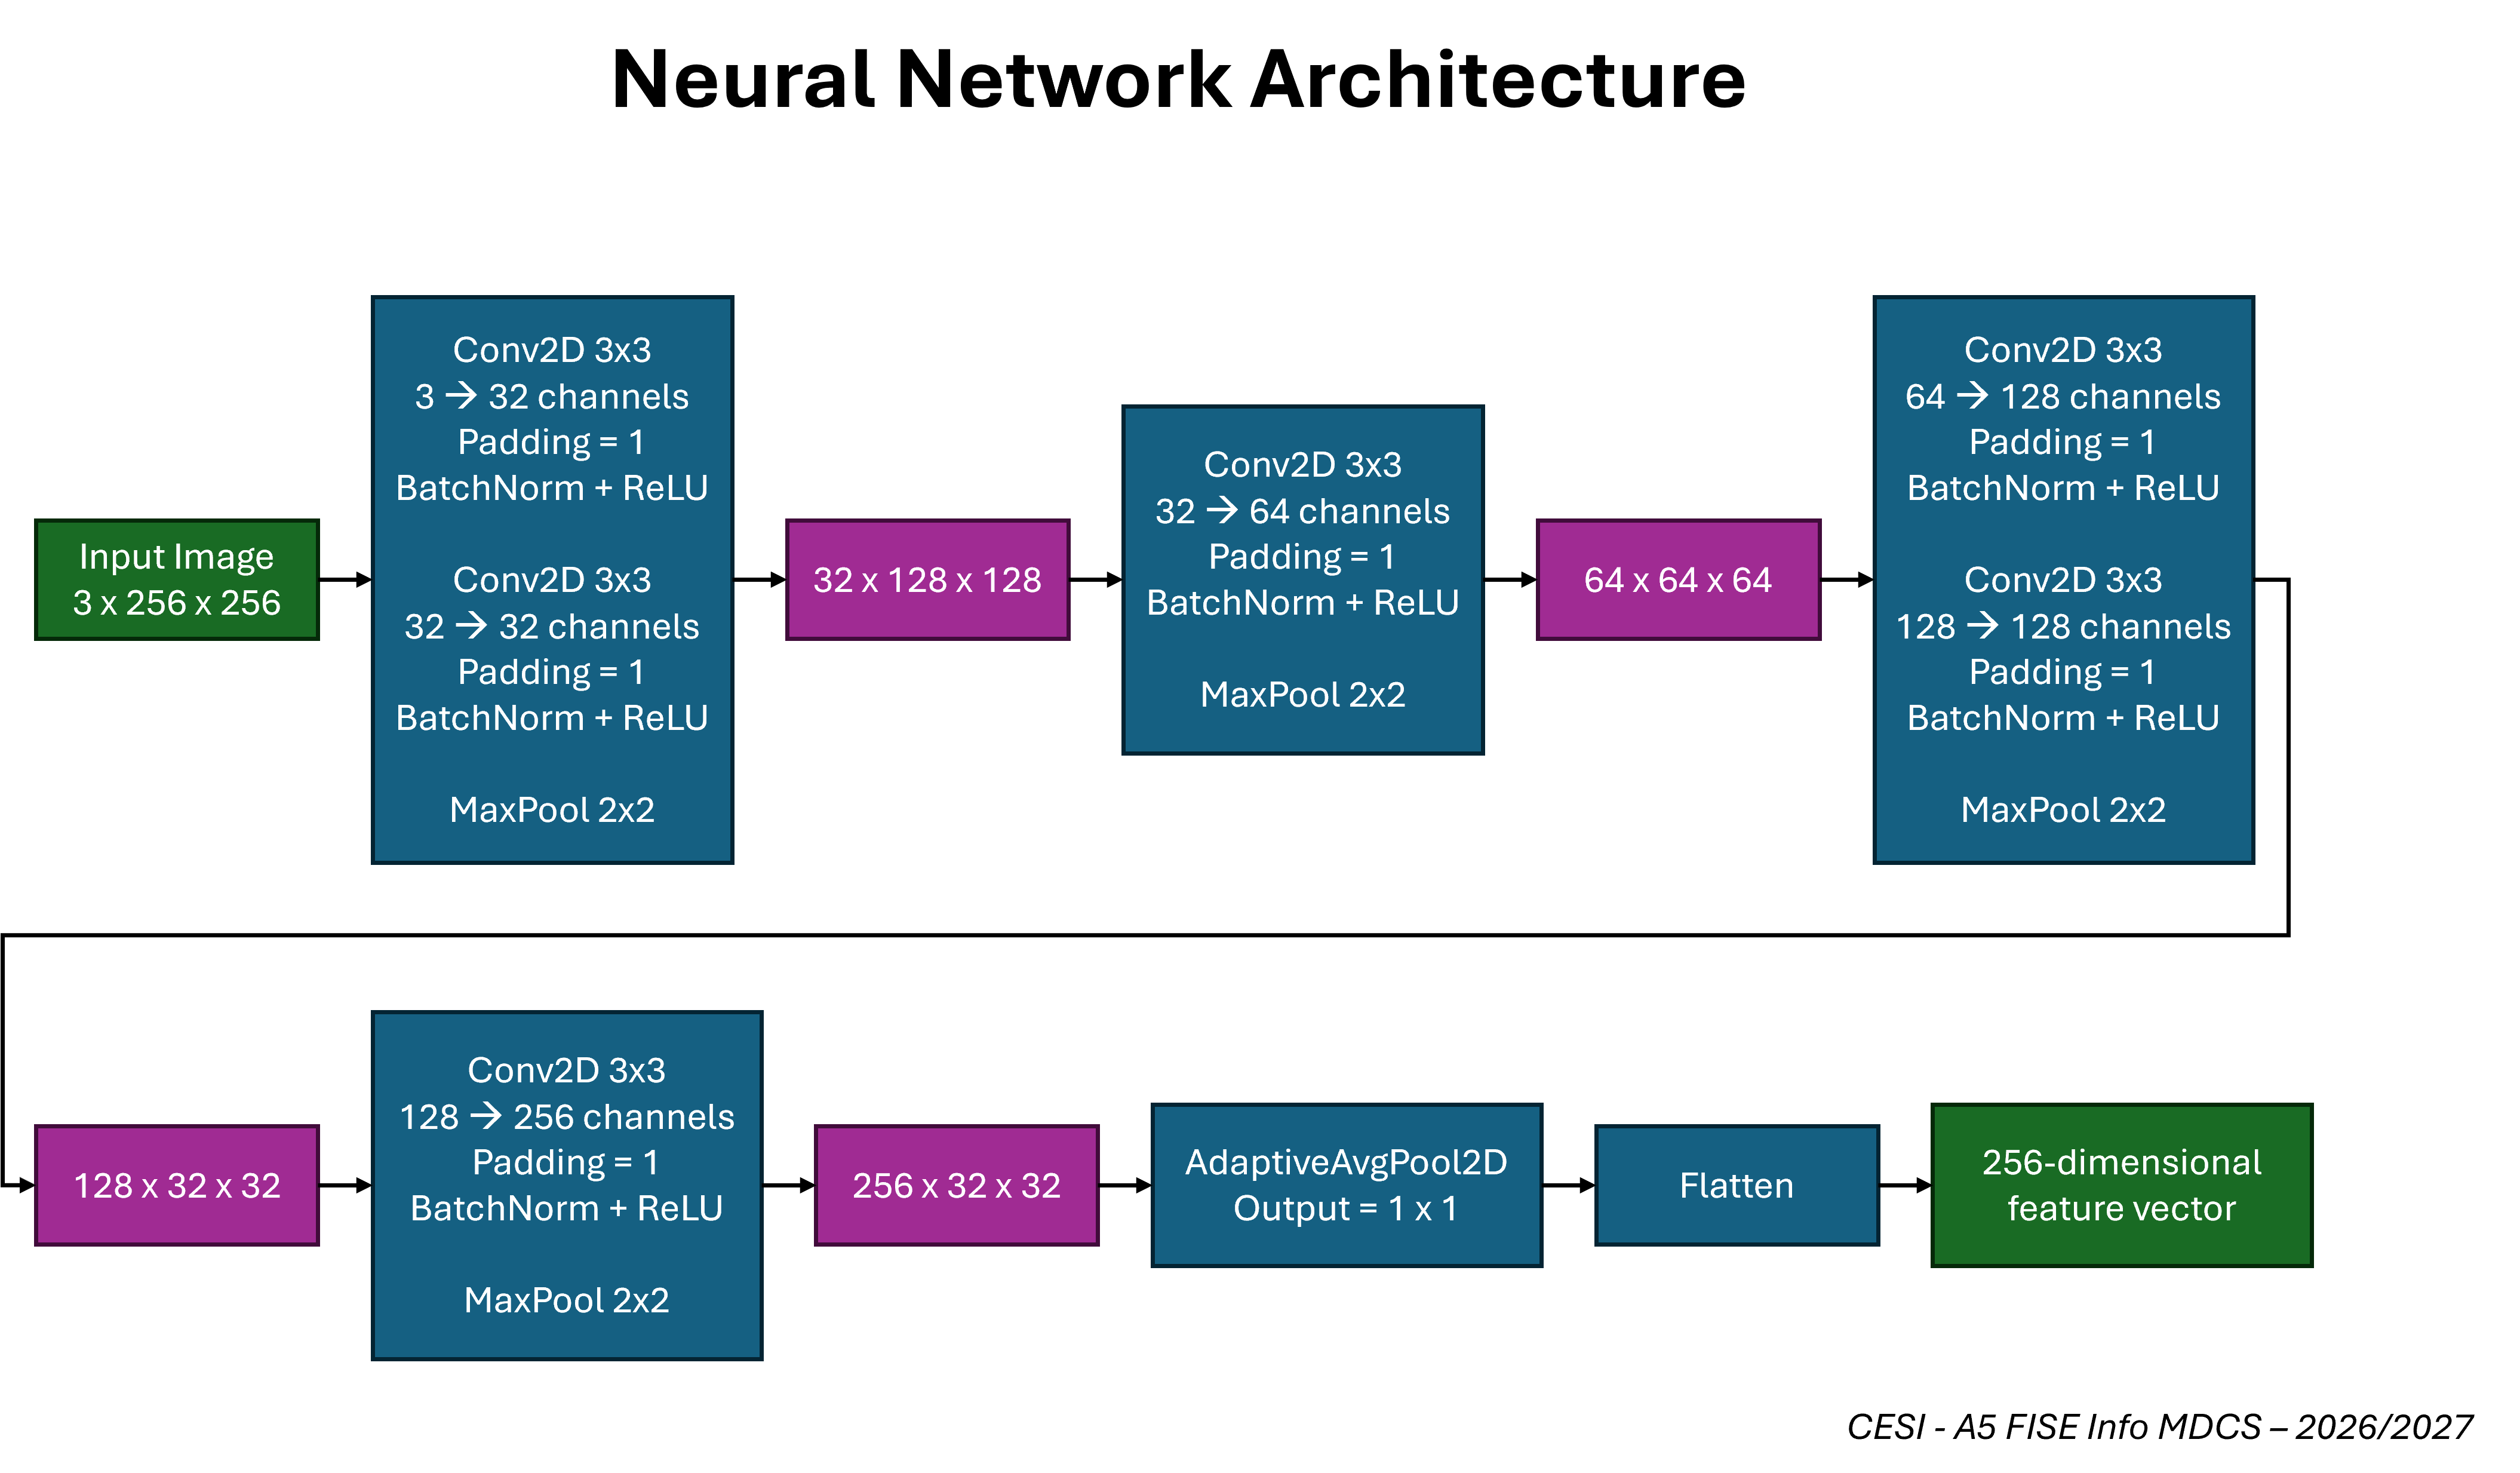

Next step is building CNN based on the above architecture. This architecture includes BatchNorm2d that helps stabilize the learning process, whereas Dropout acts as a regularization technique to improve the model's ability to generalize to unseen data.

In [8]:
# ============================================================
# CNN
# ============================================================

class PhotoClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

We will first import the path to the images in memory. We will also separate them in labels depending on the name of the folder they are in.

For this first step, we will only train our model on the folders Photo and Paintings.
Please ensure that the name of the folder containgins the photo is written for the variable "true_label"

In [9]:
# ============================================================
# MAIN
# ============================================================


dataset_dir = "Datasets_separated_step1_256"  # Should contain two folders: "Photo" and "Paintings"
true_label = "Photo"                          # Should contain the name of the folder containing the photos

images = []
labels = []

# ========================================================
# CHARGEMENT DES CHEMINS
# ========================================================

i = 0

for label_name in os.listdir(dataset_dir):

    label_dir = os.path.join(dataset_dir, label_name)

    if not os.path.isdir(label_dir):
        continue

    if label_name == true_label:
        label = 1
    else:
        label = 0

    for filename in os.listdir(label_dir):

        filepath = os.path.join(label_dir, filename)

        if os.path.isfile(filepath):

            if i % 10000 == 0:
                print(i, "images")

            images.append(filepath)
            labels.append(label)

            i += 1

print("Nombre total d'images :", len(images))

# ========================================================
# TRAIN / TEST
# ========================================================

train_images, test_images, train_labels, test_labels = train_test_split(
    images,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Train :", len(train_images))
print("Test  :", len(test_images))


0 images
10000 images
Nombre total d'images : 19993
Train : 15994
Test  : 3999


Then we give our datasets to our class to prepare to load them the variable NUM_WORKERS present in the Dataloaders correspond to the multithreading. Without it the training is simply longer. In this delivrable, they are set to 0 to ensure compatibility with every computer.

In [10]:
# ========================================================
# DATASETS
# ========================================================

train_dataset = ImageDataset(
    train_images,
    train_labels,
    transform=transform
)

test_dataset = ImageDataset(
    test_images,
    test_labels,
    transform=transform
)

# ========================================================
# DATALOADERS
# ========================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

Instantiation of the model

In [11]:
# ========================================================
# MODEL
# ========================================================

model = PhotoClassifier().to(device)

print(model)


PhotoClassifier(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
 

We added different weight for photos (since there category is under represented compared to the other categories combined)

In [12]:
# ========================================================
# LOSS
# ========================================================

n_positive = sum(train_labels)
n_negative = len(train_labels) - n_positive

pos_weight = torch.tensor(
    [n_negative / n_positive],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("Photos :", n_positive)
print("Non-photos :", n_negative)
print("pos_weight :", pos_weight.item())

Photos : 7994
Non-photos : 8000
pos_weight : 1.0007505416870117


For the optimizer we stayed on Adam and didn't took time to test with other optimizer. It could be a future point for improvement.
We also used torch.optim.lr_scheduler.ReduceLROnPlateau to reduce the learning rate when the validation loss is starting to stop improving.
Whithout it the validation loss was starting to go up at the end of the training whereas now it ether stagnate or continue to go lower.



In [13]:
# ========================================================
# OPTIMIZER
# ========================================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)


We also added a little optimisation for time consumption and precision by using GradScaler which uses two numerical format for float (between float32 and float 16).

In [14]:
# ========================================================
# MIXED PRECISION
# ========================================================

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

Once our model is parametered we start the learning, with 6 of patience for the early stopping. The patience depends on the test loss improving or not. At the end the best model will be saved as "photo_classifier_best.pth"


In [15]:

# ========================================================
# HISTORIQUES
# ========================================================

train_losses = []
test_losses = []

train_accuracies = []
test_accuracies = []

# ========================================================
# TRAINING
# ========================================================

# ============================================================
# EARLY STOPPING
# ============================================================

PATIENCE = 6

best_test_loss = float("inf")
epochs_without_improvement = 0
best_model_path = "photo_classifier_best.pth"

for epoch in range(EPOCHS):

    start_epoch = time.perf_counter()

    print()
    print("=" * 60)
    print(f"EPOCH {epoch + 1}/{EPOCHS}")
    print("=" * 60)

    # ----------------------------------------------------
    # TRAIN
    # ----------------------------------------------------

    model.train()

    train_loss = torch.zeros(1, device=device)
    train_correct = torch.zeros(1, device=device)
    train_total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.float().unsqueeze(1).to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        train_loss += loss.detach() * images.size(0)

        predictions = outputs >= 0

        train_correct += (
            predictions == labels.bool()
        ).sum()

        train_total += images.size(0)

        # Progression
        if (batch_idx + 1) % 20 == 0:

            percentage = (
                (batch_idx + 1)
                / len(train_loader)
                * 100
            )

            print(
                f"Progression : {percentage:.1f}%"
            )

    # ----------------------------------------------------
    # TRAIN METRICS
    # ----------------------------------------------------

    train_loss = (
        train_loss / train_total
    ).item()

    train_accuracy = (
        train_correct / train_total
    ).item()

    print()
    print(
        f"Train Loss     : {train_loss:.4f}"
    )

    print(
        f"Train Accuracy : {train_accuracy:.4f}"
    )

    # ----------------------------------------------------
    # TEST
    # ----------------------------------------------------

    model.eval()

    test_loss = torch.zeros(1, device=device)
    test_correct = torch.zeros(1, device=device)
    test_total = 0

    y_true = []
    y_prob = []
    y_pred = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.float().unsqueeze(1).to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            probabilities = torch.sigmoid(outputs)

            predictions = probabilities >= 0.5

            test_loss += (
                loss.detach()
                * images.size(0)
            )

            test_correct += (
                predictions == labels.bool()
            ).sum()

            test_total += images.size(0)

            # CPU uniquement pour les métriques finales
            y_true.extend(
                labels.cpu().numpy().ravel()
            )

            y_prob.extend(
                probabilities.cpu().numpy().ravel()
            )

            y_pred.extend(
                predictions.cpu().numpy().ravel()
            )

    # ----------------------------------------------------
    # TEST METRICS
    # ----------------------------------------------------

    test_loss = (
        test_loss / test_total
    ).item()

    test_accuracy = (
        test_correct / test_total
    ).item()

    scheduler.step(test_loss)

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = np.array(y_pred)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # ----------------------------------------------------
    # HISTORIQUES
    # ----------------------------------------------------

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    # ----------------------------------------------------
    # AFFICHAGE
    # ----------------------------------------------------

    print()
    print(
        f"Test Loss      : {test_loss:.4f}"
    )

    print(
        f"Test Accuracy  : {test_accuracy:.4f}"
    )

    print(
        f"Precision      : {precision:.4f}"
    )

    print(
        f"Recall         : {recall:.4f}"
    )

    print(
        f"F1-score       : {f1:.4f}"
    )

    end_epoch = time.perf_counter()

    print()
    print(
        f"Temps epoch : "
        f"{end_epoch - start_epoch:.2f} secondes"
    )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if test_loss < best_test_loss:

        best_test_loss = test_loss
        epochs_without_improvement = 0

        # Sauvegarde du meilleur modèle
        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            f"Nouvelle meilleure test loss : "
            f"{best_test_loss:.4f}"
        )

        best_test_accuracy = test_accuracy
        best_precision = precision
        best_recall = recall
        best_f1 = f1

    else:

        epochs_without_improvement += 1

        print(
            f"Pas d'amélioration depuis "
            f"{epochs_without_improvement} epoch(s)"
        )

        if epochs_without_improvement >= PATIENCE:

            print()
            print("=" * 60)
            print("EARLY STOPPING")
            print(
                f"Arrêt après {epoch + 1} epochs."
            )
            print(
                f"Meilleure test loss : "
                f"{best_test_loss:.4f}"
            )
            print("=" * 60)

            break




EPOCH 1/50
Progression : 4.0%
Progression : 8.0%
Progression : 12.0%
Progression : 16.0%
Progression : 20.0%
Progression : 24.0%
Progression : 28.0%
Progression : 32.0%
Progression : 36.0%
Progression : 40.0%
Progression : 44.0%
Progression : 48.0%
Progression : 52.0%
Progression : 56.0%
Progression : 60.0%
Progression : 64.0%
Progression : 68.0%
Progression : 72.0%
Progression : 76.0%
Progression : 80.0%
Progression : 84.0%
Progression : 88.0%
Progression : 92.0%
Progression : 96.0%
Progression : 100.0%

Train Loss     : 0.4658
Train Accuracy : 0.7842

Test Loss      : 0.4183
Test Accuracy  : 0.8047
Precision      : 0.8939
Recall         : 0.6913
F1-score       : 0.7797

Temps epoch : 61.66 secondes
Nouvelle meilleure test loss : 0.4183

EPOCH 2/50
Progression : 4.0%
Progression : 8.0%
Progression : 12.0%
Progression : 16.0%
Progression : 20.0%
Progression : 24.0%
Progression : 28.0%
Progression : 32.0%
Progression : 36.0%
Progression : 40.0%
Progression : 44.0%
Progression : 48.0%
P

Then we show all the metrics

best test loss: 0.09069786965847015
Test Accuracy  : 0.9680
Precision      : 0.9708
Recall         : 0.9650
F1-score       : 0.9679

Modèle sauvegardé.


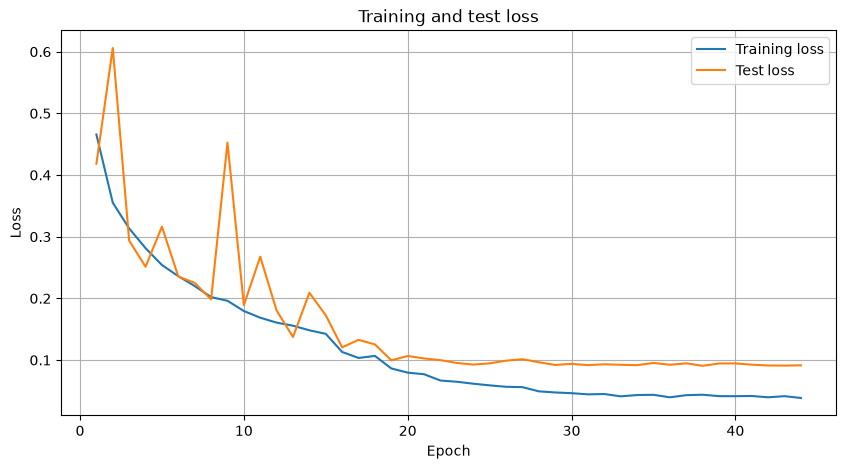

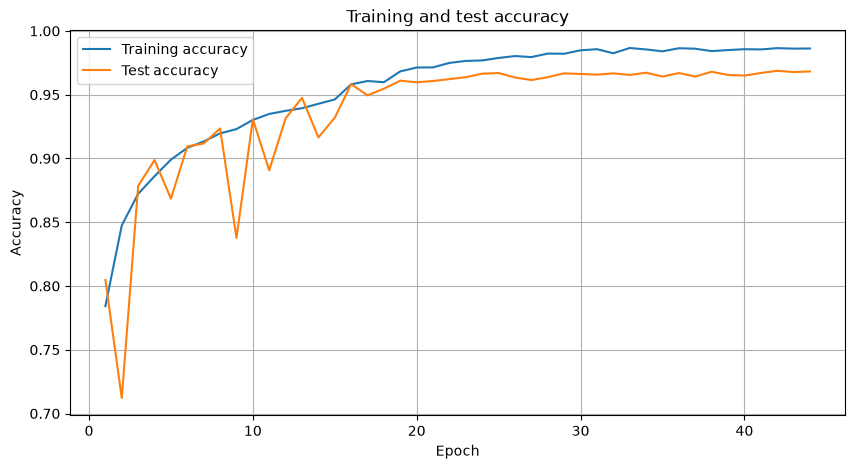

In [16]:
print("best test loss:", best_test_loss)

print(
    f"Test Accuracy  : {best_test_accuracy:.4f}"
)

print(
    f"Precision      : {best_precision:.4f}"
)

print(
    f"Recall         : {best_recall:.4f}"
)

print(
    f"F1-score       : {best_f1:.4f}"
)
# ========================================================
# SAUVEGARDE
# ========================================================

torch.save(
    model.state_dict(),
    "photo_classifier.pth"
)

print()
print("Modèle sauvegardé.")

# ========================================================
# GRAPHIQUES
# ========================================================

epochs = range(
    1,
    len(train_losses) + 1
)

# Loss
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    train_losses,
    label="Training loss"
)

plt.plot(
    epochs,
    test_losses,
    label="Test loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and test loss")
plt.legend()
plt.grid()

plt.show()

# Accuracy
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    train_accuracies,
    label="Training accuracy"
)

plt.plot(
    epochs,
    test_accuracies,
    label="Test accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and test accuracy")
plt.legend()
plt.grid()

plt.show()

### Results analysis

Overall, the performance of the first step of the model is quite good.

We can see that both the training and test loss curve quickly diminishes to almost zero while having a difference of less than 1%.

The same can be said for the training and test accuracy curve, who quickly climb up from around 70% accuracy to 90%, and plateaus at around 96% with a difference of around 2% between the training and test curves.

A high stable accuracy and a low stable loss indicates that our model isn't overfitting, thanks to the early stopping.




## Step 2 - Training with all the datasets

In this second step the model will not change but we will train the model again with every datasets this time. This will allow us to perfect the previous model's training as well as incorporate new training elements.

The start is the same as the first one but we load Photo and paintings, separate them by using the same train_test_split as the step one to ensure we don't have any data leakage.

We then laod the others datasets, spits them and add them to the split we already did.

We also changed the learning rate to not have to much impact the pre prepared weights

To do so you will need to indicate two different folders to load correctly the datasets (refers on the comments in front of the variables below)

In [17]:
dataset_dir        = "Datasets_separated_step1_256" # Should contain two folders: "Photo" and "Paintings" of size 256x256
dataset_dir_part_2 = "Datasets_separated_step2_256" # Should contain the remaining folders : "Schematics", "Skecth" and "Text" of size 256x256

LEARNING_RATE = 0.0001

images_A = []
labels_A = []

# ========================================================
# CHARGEMENT DES CHEMINS
# ========================================================

i = 0

for label_name in os.listdir(dataset_dir):

    label_dir = os.path.join(dataset_dir, label_name)

    if not os.path.isdir(label_dir):
        continue

    if label_name == "Photo":
        label = 1
    else:
        label = 0

    for filename in os.listdir(label_dir):

        filepath = os.path.join(label_dir, filename)

        if os.path.isfile(filepath):

            if i % 10000 == 0:
                print(i, "images")

            images_A.append(filepath)
            labels_A.append(label)

            i += 1

print("Nombre total d'images :", len(images_A))

# ========================================================
# TRAIN / TEST
# ========================================================

train_A, test_A, labels_train_A, labels_test_A = train_test_split(
    images_A,
    labels_A,
    test_size=0.2,
    random_state=42,
    stratify=labels_A
)



images_B = []
labels_B = []

# ========================================================
# CHARGEMENT DES CHEMINS
# ========================================================

i = 0

for label_name in os.listdir(dataset_dir_part_2):

    label_dir = os.path.join(dataset_dir_part_2, label_name)

    if not os.path.isdir(label_dir):
        continue

    if label_name == "Photo":
        label = 1
    else:
        label = 0

    for filename in os.listdir(label_dir):

        filepath = os.path.join(label_dir, filename)

        if os.path.isfile(filepath):

            if i % 10000 == 0:
                print(i, "images")

            images_B.append(filepath)
            labels_B.append(label)

            i += 1

print("Nombre total d'images :", len(images_B))

train_B, test_B, labels_train_B, labels_test_B = train_test_split(
    images_B,
    labels_B,
    test_size=0.2,
    random_state=42,
    stratify=labels_B
)


train_images = train_A + train_B
train_labels = labels_train_A + labels_train_B

test_images = test_A + test_B
test_labels = labels_test_A + labels_test_B

print("Train :", len(train_images))
print("Test  :", len(test_images))

0 images
10000 images
Nombre total d'images : 19993
0 images
10000 images
20000 images
Nombre total d'images : 21402
Train : 33115
Test  : 8280


In [18]:
# ========================================================
# DATASETS
# ========================================================

train_dataset = ImageDataset(
    train_images,
    train_labels,
    transform=transform
)

test_dataset = ImageDataset(
    test_images,
    test_labels,
    transform=transform
)

# ========================================================
# DATALOADERS
# ========================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

# Vérification
images_batch, labels_batch = next(iter(train_loader))

print("Batch :", images_batch.shape)
print("Labels :", labels_batch.shape)

Batch : torch.Size([32, 3, 256, 256])
Labels : torch.Size([32])


We load the model we previously saved

Please change the path_to_model to your model

In [19]:
%pip install safetensors

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [20]:
path_to_model = "C:/Users/JANDL Maëlice/Desktop/Devoir A5/Data science/Option-IA-A5-CESI/Livrable 1/photo_classifier_best.pth"

# ========================================================
# MODEL
# ========================================================

model = PhotoClassifier().to(device)

model.load_state_dict(
    torch.load(
        path_to_model,
        map_location=device
    )
)

print(model)

PhotoClassifier(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
 

Then we train our model the same way than before

Photos : 7994
Non-photos : 25121
pos_weight : 3.142481803894043

EPOCH 1/50
Progression : 1.9%
Progression : 3.9%
Progression : 5.8%
Progression : 7.7%
Progression : 9.7%
Progression : 11.6%
Progression : 13.5%
Progression : 15.5%
Progression : 17.4%
Progression : 19.3%
Progression : 21.3%
Progression : 23.2%
Progression : 25.1%
Progression : 27.1%
Progression : 29.0%
Progression : 30.9%
Progression : 32.9%
Progression : 34.8%
Progression : 36.7%
Progression : 38.6%
Progression : 40.6%
Progression : 42.5%
Progression : 44.4%
Progression : 46.4%
Progression : 48.3%
Progression : 50.2%
Progression : 52.2%
Progression : 54.1%
Progression : 56.0%
Progression : 58.0%
Progression : 59.9%
Progression : 61.8%
Progression : 63.8%
Progression : 65.7%
Progression : 67.6%
Progression : 69.6%
Progression : 71.5%
Progression : 73.4%
Progression : 75.4%
Progression : 77.3%
Progression : 79.2%
Progression : 81.2%
Progression : 83.1%
Progression : 85.0%
Progression : 87.0%
Progression : 88.9%
Progressi

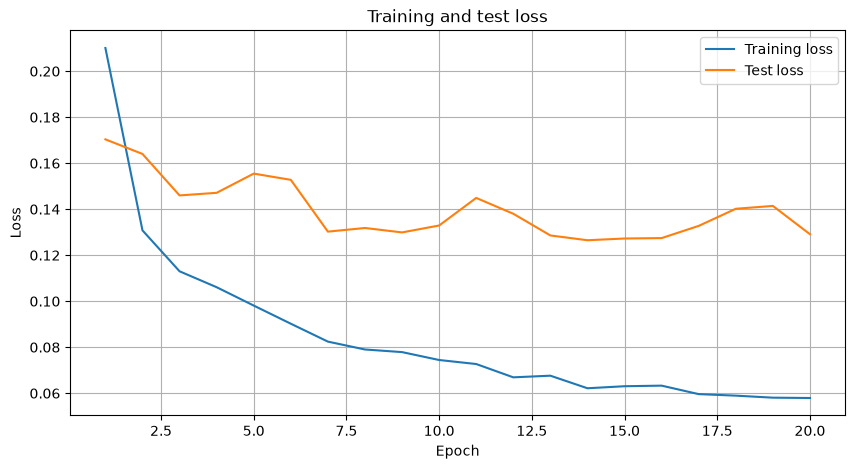

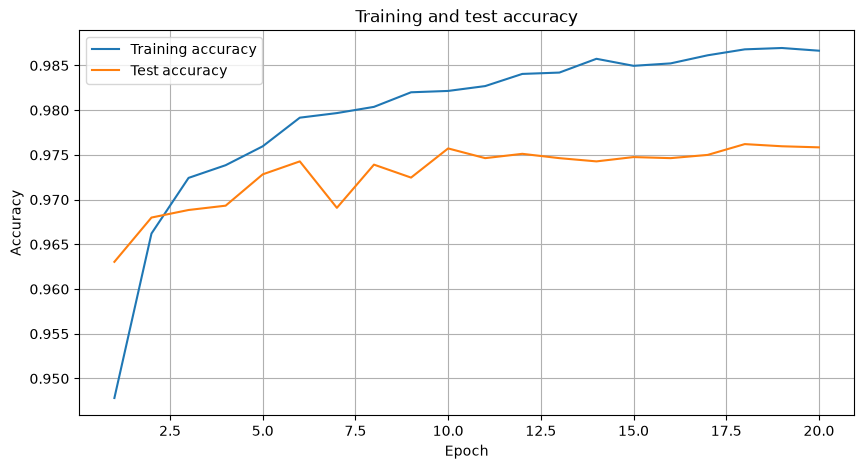

In [21]:
# ========================================================
# LOSS
# ========================================================

n_positive = sum(train_labels)
n_negative = len(train_labels) - n_positive

pos_weight = torch.tensor(
    [n_negative / n_positive],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("Photos :", n_positive)
print("Non-photos :", n_negative)
print("pos_weight :", pos_weight.item())

# ========================================================
# OPTIMIZER
# ========================================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

# ========================================================
# MIXED PRECISION
# ========================================================

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

# ========================================================
# HISTORIQUES
# ========================================================

train_losses = []
test_losses = []

train_accuracies = []
test_accuracies = []

# ========================================================
# TRAINING
# ========================================================

# ============================================================
# EARLY STOPPING
# ============================================================

PATIENCE = 6

best_test_loss = float("inf")
epochs_without_improvement = 0
best_model_path = "photo_classifier_best.pth"

for epoch in range(EPOCHS):

    start_epoch = time.perf_counter()

    print()
    print("=" * 60)
    print(f"EPOCH {epoch + 1}/{EPOCHS}")
    print("=" * 60)

    # ----------------------------------------------------
    # TRAIN
    # ----------------------------------------------------

    model.train()

    train_loss = torch.zeros(1, device=device)
    train_correct = torch.zeros(1, device=device)
    train_total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.float().unsqueeze(1).to(
            device,
            non_blocking=True
        )

        # Très légèrement plus rapide
        optimizer.zero_grad(set_to_none=True)

        # Mixed precision
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        # Backpropagation
        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        # Statistiques GPU
        train_loss += loss.detach() * images.size(0)

        predictions = outputs >= 0

        train_correct += (
            predictions == labels.bool()
        ).sum()

        train_total += images.size(0)

        # Progression
        if (batch_idx + 1) % 20 == 0:

            percentage = (
                (batch_idx + 1)
                / len(train_loader)
                * 100
            )

            print(
                f"Progression : {percentage:.1f}%"
            )

    # ----------------------------------------------------
    # TRAIN METRICS
    # ----------------------------------------------------

    train_loss = (
        train_loss / train_total
    ).item()

    train_accuracy = (
        train_correct / train_total
    ).item()

    print()
    print(
        f"Train Loss     : {train_loss:.4f}"
    )

    print(
        f"Train Accuracy : {train_accuracy:.4f}"
    )

    # ----------------------------------------------------
    # TEST
    # ----------------------------------------------------

    model.eval()

    test_loss = torch.zeros(1, device=device)
    test_correct = torch.zeros(1, device=device)
    test_total = 0

    y_true = []
    y_prob = []
    y_pred = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.float().unsqueeze(1).to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            probabilities = torch.sigmoid(outputs)

            predictions = probabilities >= 0.5

            test_loss += (
                loss.detach()
                * images.size(0)
            )

            test_correct += (
                predictions == labels.bool()
            ).sum()

            test_total += images.size(0)

            # CPU uniquement pour les métriques finales
            y_true.extend(
                labels.cpu().numpy().ravel()
            )

            y_prob.extend(
                probabilities.cpu().numpy().ravel()
            )

            y_pred.extend(
                predictions.cpu().numpy().ravel()
            )

    # ----------------------------------------------------
    # TEST METRICS
    # ----------------------------------------------------

    test_loss = (
        test_loss / test_total
    ).item()

    test_accuracy = (
        test_correct / test_total
    ).item()

    scheduler.step(test_loss)

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = np.array(y_pred)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # ----------------------------------------------------
    # HISTORIQUES
    # ----------------------------------------------------

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    # ----------------------------------------------------
    # AFFICHAGE
    # ----------------------------------------------------

    print()
    print(
        f"Test Loss      : {test_loss:.4f}"
    )

    print(
        f"Test Accuracy  : {test_accuracy:.4f}"
    )

    print(
        f"Precision      : {precision:.4f}"
    )

    print(
        f"Recall         : {recall:.4f}"
    )

    print(
        f"F1-score       : {f1:.4f}"
    )

    end_epoch = time.perf_counter()

    print()
    print(
        f"Temps epoch : "
        f"{end_epoch - start_epoch:.2f} secondes"
    )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if test_loss < best_test_loss:

        best_test_loss = test_loss
        epochs_without_improvement = 0

        # Sauvegarde du meilleur modèle
        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            f"Nouvelle meilleure test loss : "
            f"{best_test_loss:.4f}"
        )

        best_test_accuracy = test_accuracy
        best_precision = precision
        best_recall = recall
        best_f1 = f1

    else:

        epochs_without_improvement += 1

        print(
            f"Pas d'amélioration depuis "
            f"{epochs_without_improvement} epoch(s)"
        )

        if epochs_without_improvement >= PATIENCE:

            print()
            print("=" * 60)
            print("EARLY STOPPING")
            print(
                f"Arrêt après {epoch + 1} epochs."
            )
            print(
                f"Meilleure test loss : "
                f"{best_test_loss:.4f}"
            )
            print("=" * 60)

            break

print("best test loss:", best_test_loss)

print(
    f"Test Accuracy  : {best_test_accuracy:.4f}"
)

print(
    f"Precision      : {best_precision:.4f}"
)

print(
    f"Recall         : {best_recall:.4f}"
)

print(
    f"F1-score       : {best_f1:.4f}"
)
# ========================================================
# SAUVEGARDE
# ========================================================

torch.save(
    model.state_dict(),
    "photo_classifier.pth"
)

print()
print("Modèle sauvegardé.")

# ========================================================
# GRAPHIQUES
# ========================================================

epochs = range(
    1,
    len(train_losses) + 1
)

# Loss
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    train_losses,
    label="Training loss"
)

plt.plot(
    epochs,
    test_losses,
    label="Test loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and test loss")
plt.legend()
plt.grid()

plt.show()

# Accuracy
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    train_accuracies,
    label="Training accuracy"
)

plt.plot(
    epochs,
    test_accuracies,
    label="Test accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and test accuracy")
plt.legend()
plt.grid()

plt.show()

### Results analysis

As we can see, both curves are very similar to the first step's except that they have much better performance from the start.

Even better, the accuracy has increased further to almost 98% while the loss stayed around 1%.

Just like before, the early stopping prevented any overfitting.

# Conclusion

In this first delivrable, we have processed the images so they are ready for machine learning, designed a model with dropout, regularization and early stopping and trained it in two steps: the first one only on the photos and pictures datasets, and the second one on all the datasets.

This two-step process allowed us to attain a precision of almost 98% with a loss of around 1%, which are great metrics for a model.

Other methods such as noising/denoising and image captionning could be tested to see if it further improves the model's performances.